# *Import Libraries*:-

In [1]:
# import pandas 
import pandas as pd
import numpy as np
from scipy import stats
import statistics as st
import seaborn as sns 
import matplotlib.pyplot as plt 


In [2]:
# load a specific dataset 
tips = sns.load_dataset("tips")
iris = sns.load_dataset("iris")

In [3]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [22]:
tips.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [24]:
tips.describe(include='number')

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [25]:
tips.describe(include='category')

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


In [92]:
for i in tips.columns:
    if tips[i].dtype=='category':
        tips[i] = tips[i].replace("",None)
        tips[i] = tips[i].replace(" ",None)
    elif tips[i].dtype=='number':
        tips[i] = tips[i].replace("",np.nan)

In [26]:
# Check Null value & Duplicated Records :- 
tips.isnull().sum().any()

np.False_

In [7]:
tips.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [27]:
tips.duplicated().sum().any()

np.True_

In [28]:
tips.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
239    False
240    False
241    False
242    False
243    False
Length: 244, dtype: bool

In [29]:
tips[tips.duplicated()]

,total_bill,tip,sex,smoker,day,time,size
202,13.0,2.0,Female,Yes,Thur,Lunch,2


In [9]:
new_tips = tips.copy()

In [10]:
new_tips.drop_duplicates()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [11]:
new_tips.drop_duplicates(inplace=True)

/var/folders/vl/5d3h1_r53791k9b7s8cvn6080000gn/T/ipykernel_1325/1213572216.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  new_tips.drop_duplicates(inplace=True)


In [12]:
new_tips.duplicated().sum().any()

np.False_

In [30]:
new_tips.info()

<class 'pandas.DataFrame'>
Index: 243 entries, 0 to 243
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   total_bill   243 non-null    float32 
 1   tip          243 non-null    float32 
 2   gender       243 non-null    category
 3   smoker       243 non-null    category
 4   Day          243 non-null    category
 5   time         243 non-null    category
 6   size         243 non-null    int8    
 7   Final_bills  243 non-null    float32 
dtypes: category(4), float32(3), int8(1)
memory usage: 6.5 KB



# *Memory management:-*

In [91]:
for i in new_tips.columns:
    if new_tips[i].dtype=='category':
        new_tips[i] = pd.Categorical(new_tips[i])
    elif new_tips[i].dtype=='float':
        new_tips[i] = pd.to_numeric(new_tips[i],downcast='float')
    elif new_tips[i].dtype=='int':
        new_tips[i] = pd.to_numeric(new_tips[i],downcast='integer')

In [32]:
new_tips.info()

<class 'pandas.DataFrame'>
Index: 243 entries, 0 to 243
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   total_bill   243 non-null    float32 
 1   tip          243 non-null    float32 
 2   gender       243 non-null    category
 3   smoker       243 non-null    category
 4   Day          243 non-null    category
 5   time         243 non-null    category
 6   size         243 non-null    int8    
 7   Final_bills  243 non-null    float32 
dtypes: category(4), float32(3), int8(1)
memory usage: 6.5 KB


In [93]:
# rename , drop ,create new columns:-
new_tips.rename(columns={"sex":"Gender","day":"Day"},inplace=True)

/var/folders/vl/5d3h1_r53791k9b7s8cvn6080000gn/T/ipykernel_1325/1246752110.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  new_tips.rename(columns={"sex":"Gender","day":"Day"},inplace=True)


In [94]:
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
0,16.99,1.01,Female,NaN,Sun,Dinner,2,17.840000,Lowest Bills
1,10.34,1.66,Male,NaN,Sun,Dinner,3,10.860000,Lowest Bills
2,21.01,3.50,Male,NaN,Sun,Dinner,3,22.059999,Mid Bills
3,23.68,3.31,Male,NaN,Sun,Dinner,2,24.860001,Mid Bills
4,24.59,3.61,Female,NaN,Sun,Dinner,4,25.820000,Mid Bills


In [95]:
# create new columns :-
# 5% tax on total bill
new_tips['Final_bills'] = new_tips['total_bill'] + new_tips['total_bill'] * 0.05

# 1. Round the actual data using single brackets
new_tips['Final_bills'] = new_tips['Final_bills'].round(2)

In [96]:
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
0,16.99,1.01,Female,NaN,Sun,Dinner,2,17.840000,Lowest Bills
1,10.34,1.66,Male,NaN,Sun,Dinner,3,10.860000,Lowest Bills
2,21.01,3.50,Male,NaN,Sun,Dinner,3,22.059999,Mid Bills
3,23.68,3.31,Male,NaN,Sun,Dinner,2,24.860001,Mid Bills
4,24.59,3.61,Female,NaN,Sun,Dinner,4,25.820000,Mid Bills


In [97]:
new_tips['Double_of_tips'] = new_tips['tip'] * 2

In [98]:
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category,Double_of_tips
0,16.99,1.01,Female,NaN,Sun,Dinner,2,17.840000,Lowest Bills,2.02
1,10.34,1.66,Male,NaN,Sun,Dinner,3,10.860000,Lowest Bills,3.32
2,21.01,3.50,Male,NaN,Sun,Dinner,3,22.059999,Mid Bills,7.00
3,23.68,3.31,Male,NaN,Sun,Dinner,2,24.860001,Mid Bills,6.62
4,24.59,3.61,Female,NaN,Sun,Dinner,4,25.820000,Mid Bills,7.22


In [99]:
new_tips.drop(['Double_of_tips'],axis=1,inplace=True)

/var/folders/vl/5d3h1_r53791k9b7s8cvn6080000gn/T/ipykernel_1325/1572448243.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  new_tips.drop(['Double_of_tips'],axis=1,inplace=True)


In [100]:
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
0,16.99,1.01,Female,NaN,Sun,Dinner,2,17.840000,Lowest Bills
1,10.34,1.66,Male,NaN,Sun,Dinner,3,10.860000,Lowest Bills
2,21.01,3.50,Male,NaN,Sun,Dinner,3,22.059999,Mid Bills
3,23.68,3.31,Male,NaN,Sun,Dinner,2,24.860001,Mid Bills
4,24.59,3.61,Female,NaN,Sun,Dinner,4,25.820000,Mid Bills


In [101]:
# Transform data , Encoding ( Category into number ) 

In [102]:
def modify_fun(x):
    if x >=30:
        return "Highest bills"
    elif x >=20:
        return "Mid Bills"
    else:
        return "Lowest Bills"

In [103]:
# tital bill >= 20 , higher bill , 10-20 ( mid bill) , lowest bill
# Final_bills >=30 , Highest bill , 20-30 ( Mid Bill ) , lowest bill
new_tips['bill_category'] = new_tips['Final_bills'].apply(lambda a : "Highest bills" if a >=30 else ( "Mid Bills" if a >=20 else "Lowest Bills"))


In [104]:
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
0,16.99,1.01,Female,NaN,Sun,Dinner,2,17.840000,Lowest Bills
1,10.34,1.66,Male,NaN,Sun,Dinner,3,10.860000,Lowest Bills
2,21.01,3.50,Male,NaN,Sun,Dinner,3,22.059999,Mid Bills
3,23.68,3.31,Male,NaN,Sun,Dinner,2,24.860001,Mid Bills
4,24.59,3.61,Female,NaN,Sun,Dinner,4,25.820000,Mid Bills


In [105]:
new_tips['smoker'] = new_tips['smoker'].map({'NO':0,'Yes':1})
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
0,16.99,1.01,Female,NaN,Sun,Dinner,2,17.840000,Lowest Bills
1,10.34,1.66,Male,NaN,Sun,Dinner,3,10.860000,Lowest Bills
2,21.01,3.50,Male,NaN,Sun,Dinner,3,22.059999,Mid Bills
3,23.68,3.31,Male,NaN,Sun,Dinner,2,24.860001,Mid Bills
4,24.59,3.61,Female,NaN,Sun,Dinner,4,25.820000,Mid Bills


In [106]:
new_tips.info()

<class 'pandas.DataFrame'>
Index: 243 entries, 0 to 243
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   total_bill     243 non-null    float32 
 1   tip            243 non-null    float32 
 2   gender         243 non-null    category
 3   smoker         0 non-null      float64 
 4   Day            243 non-null    category
 5   time           243 non-null    category
 6   size           243 non-null    int8    
 7   Final_bills    243 non-null    float32 
 8   bill_category  243 non-null    str     
dtypes: category(3), float32(3), float64(1), int8(1), str(1)
memory usage: 12.7 KB


In [107]:
# Sorting , Filter , Group by  , # Visualization :-

<Axes: xlabel='Final_bills'>

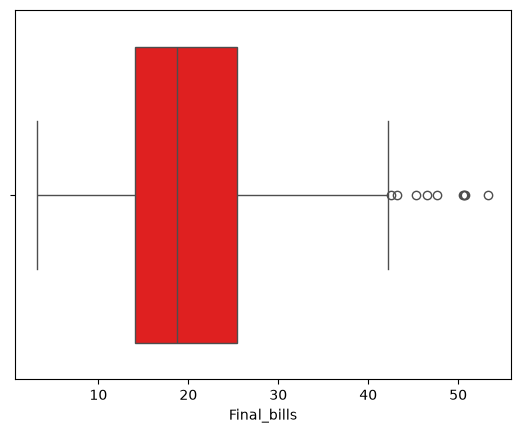

In [108]:
sns.boxplot(x = new_tips['Final_bills'],color='red')

/var/folders/vl/5d3h1_r53791k9b7s8cvn6080000gn/T/ipykernel_1325/1487779690.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Day", y="Final_bills", data=new_tips, palette="Set2")


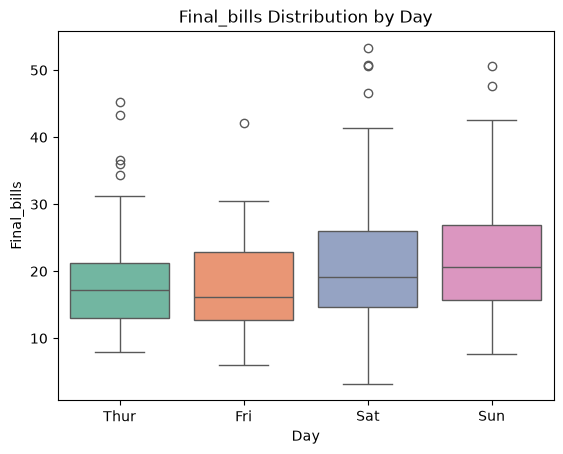

In [109]:
# create violin plot 

sns.boxplot(x="Day", y="Final_bills", data=new_tips, palette="Set2")

plt.title("Final_bills Distribution by Day")
plt.show()

/var/folders/vl/5d3h1_r53791k9b7s8cvn6080000gn/T/ipykernel_1325/572699733.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="Day", y="Final_bills", data=new_tips, palette="Set2")


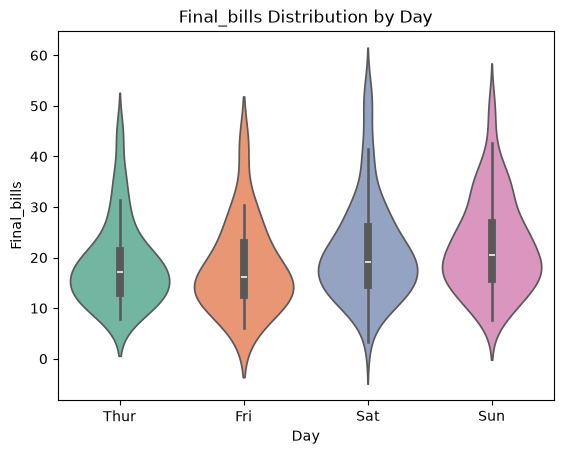

In [110]:
# Create violin plot
sns.violinplot(x="Day", y="Final_bills", data=new_tips, palette="Set2")

plt.title("Final_bills Distribution by Day")
plt.show()

/var/folders/vl/5d3h1_r53791k9b7s8cvn6080000gn/T/ipykernel_1325/2337200667.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x=new_tips["Final_bills"],color='green')


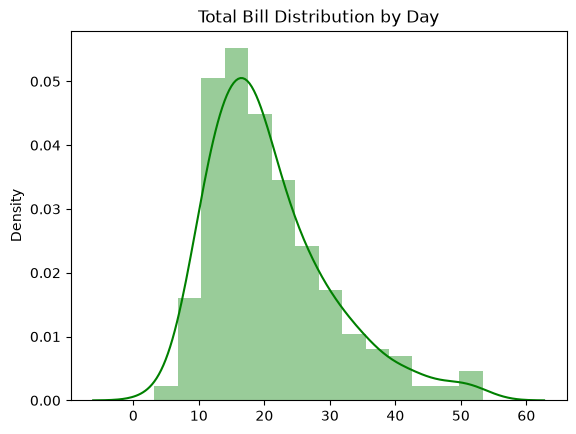

In [111]:
# Create distplot plot
sns.distplot(x=new_tips["Final_bills"],color='green')

plt.title("Total Bill Distribution by Day")
plt.show()

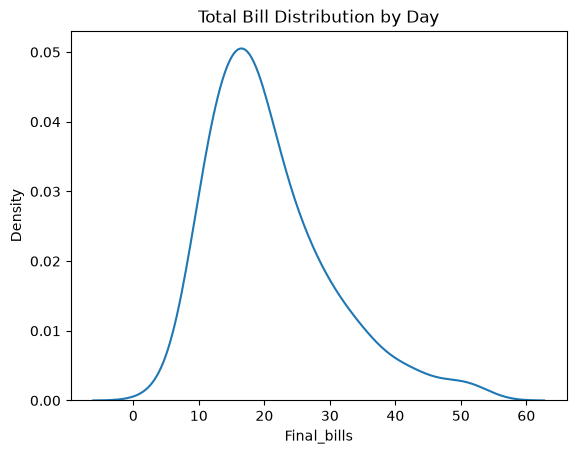

In [112]:
# Create KDE plot
sns.kdeplot(x=new_tips["Final_bills"])

plt.title("Total Bill Distribution by Day")
plt.show()

In [113]:
# Highest , lowest  ( Sorting Data )

In [114]:
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
0,16.99,1.01,Female,NaN,Sun,Dinner,2,17.840000,Lowest Bills
1,10.34,1.66,Male,NaN,Sun,Dinner,3,10.860000,Lowest Bills
2,21.01,3.50,Male,NaN,Sun,Dinner,3,22.059999,Mid Bills
3,23.68,3.31,Male,NaN,Sun,Dinner,2,24.860001,Mid Bills
4,24.59,3.61,Female,NaN,Sun,Dinner,4,25.820000,Mid Bills


In [115]:
lowest_highet_bill = new_tips.sort_values(by='Final_bills',ascending=True)
highet_lowest_bill = new_tips.sort_values(by='Final_bills',ascending=False)

In [116]:
lowest_highet_bill.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
67,3.07,1.00,Female,NaN,Sat,Dinner,1,3.22,Lowest Bills
92,5.75,1.00,Female,NaN,Fri,Dinner,2,6.04,Lowest Bills
111,7.25,1.00,Female,NaN,Sat,Dinner,1,7.61,Lowest Bills
172,7.25,5.15,Male,NaN,Sun,Dinner,2,7.61,Lowest Bills
149,7.51,2.00,Male,NaN,Thur,Lunch,2,7.89,Lowest Bills


<Axes: xlabel='total_bill', ylabel='tip'>

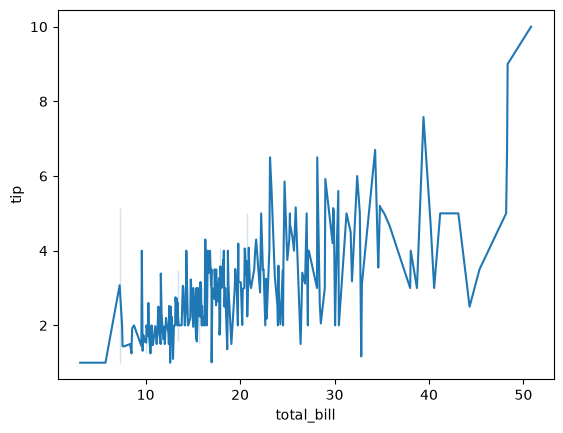

In [117]:
sns.lineplot(x = lowest_highet_bill['total_bill'],y = lowest_highet_bill['tip'])

In [118]:
highet_lowest_bill.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
170,50.810001,10.00,Male,NaN,Sat,Dinner,3,53.349998,Highest bills
212,48.330002,9.00,Male,NaN,Sat,Dinner,4,50.750000,Highest bills
59,48.270000,6.73,Male,NaN,Sat,Dinner,4,50.680000,Highest bills
156,48.169998,5.00,Male,NaN,Sun,Dinner,6,50.580002,Highest bills
182,45.349998,3.50,Male,NaN,Sun,Dinner,3,47.619999,Highest bills


In [119]:
highet_lowest_bill.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
170,50.810001,10.00,Male,NaN,Sat,Dinner,3,53.349998,Highest bills
212,48.330002,9.00,Male,NaN,Sat,Dinner,4,50.750000,Highest bills
59,48.270000,6.73,Male,NaN,Sat,Dinner,4,50.680000,Highest bills
156,48.169998,5.00,Male,NaN,Sun,Dinner,6,50.580002,Highest bills
182,45.349998,3.50,Male,NaN,Sun,Dinner,3,47.619999,Highest bills


In [120]:
new_tips.info()

<class 'pandas.DataFrame'>
Index: 243 entries, 0 to 243
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   total_bill     243 non-null    float32 
 1   tip            243 non-null    float32 
 2   gender         243 non-null    category
 3   smoker         0 non-null      float64 
 4   Day            243 non-null    category
 5   time           243 non-null    category
 6   size           243 non-null    int8    
 7   Final_bills    243 non-null    float32 
 8   bill_category  243 non-null    str     
dtypes: category(3), float32(3), float64(1), int8(1), str(1)
memory usage: 12.7 KB


In [121]:
new_tips['bill_category'] = pd.Categorical(new_tips['bill_category'])

In [122]:
# cat_col = new_tips.select_dtypes(include=['category','str']) 
cat_col = new_tips.select_dtypes(include='category') 
num_col = new_tips.select_dtypes(include='number') 

In [123]:
cat_col.head()

,gender,Day,time,bill_category
0,Female,Sun,Dinner,Lowest Bills
1,Male,Sun,Dinner,Lowest Bills
2,Male,Sun,Dinner,Mid Bills
3,Male,Sun,Dinner,Mid Bills
4,Female,Sun,Dinner,Mid Bills


In [124]:
num_col.head()

,total_bill,tip,smoker,size,Final_bills
0,16.99,1.01,NaN,2,17.840000
1,10.34,1.66,NaN,3,10.860000
2,21.01,3.50,NaN,3,22.059999
3,23.68,3.31,NaN,2,24.860001
4,24.59,3.61,NaN,4,25.820000


In [131]:
# visulization :-
# cat_col['Gender'].value_counts()

In [132]:
# cat_col['Gender'].value_counts(normalize=True)* 100

In [133]:
# cat_col['Gender'].value_counts(normalize=True).plot(kind='bar',color='pink')

<Axes: >

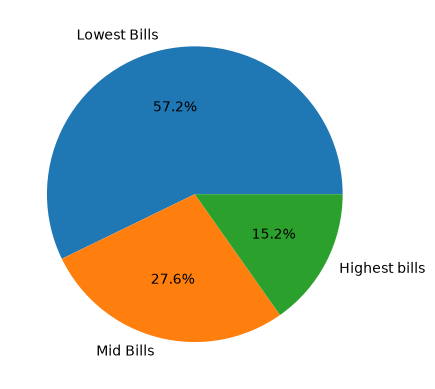

In [130]:
cat_col['bill_category'].value_counts(normalize=True).plot(kind='pie',color='pink',autopct='%1.1f%%')


In [6]:
tips.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [10]:
tips.describe(include='number')

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [12]:
tips.describe(include='category')

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


In [7]:
iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [13]:
iris.describe(include='str')

,species
count,150
unique,3
top,setosa
freq,50
